In [130]:
from sklearn.datasets import make_classification
import numpy as np

In [131]:
X,y=make_classification(n_samples=100,n_features=2,n_informative=1,n_redundant=0,
                       n_classes=2,n_clusters_per_class=1,random_state=41,hypercube=False,
                       class_sep=20)

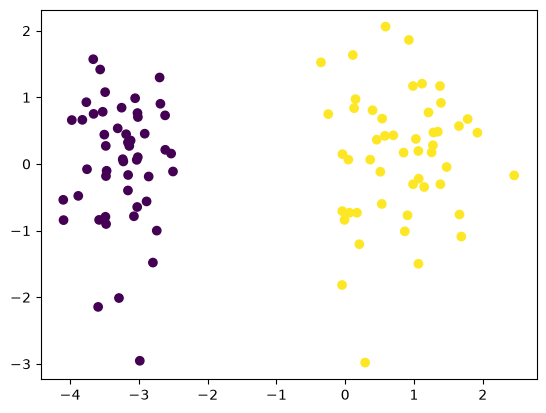

In [132]:
import matplotlib.pyplot as plt
plt.scatter(X[:,0],X[:,1],c=y)

In [133]:
from sklearn.linear_model import LogisticRegression


In [134]:
lr=LogisticRegression(penalty=None,solver='sag')
lr.fit(X,y)

C:\Users\User\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\User\anaconda3\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'sag'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may no

In [135]:
m1=lr.coef_[0][0]/lr.coef_[0][1]
b1=lr.intercept_/lr.coef_[0][1]

In [136]:
x_input=np.linspace(-3,3,100)
y_input1=m1*x_input+b1

In [137]:
lr.intercept_



array([5.776614])

In [138]:
lr.coef_

array([[4.79772566, 0.20222092]])

In [139]:
def MyLogisticRegression(X,y):
    X=np.insert(X,0,1,axis=1)
    w=np.ones(X.shape[1])
    lr=0.9
    for i in range(2000):
        xw=np.dot(X,w)
        y_hat=1/(1+np.exp(-xw))
        w=w+lr*(np.dot((y-y_hat),X))/X.shape[0]
    return w[0],w[1:]


In [140]:
amr=MyLogisticRegression(X,y)

In [141]:
print(amr)

(np.float64(5.507220909410651), array([4.61222466, 0.19227625]))


In [142]:
inter=amr[0]
print(inter)

5.507220909410651


In [143]:
coef=amr[1]

In [144]:
print(coef)

[4.61222466 0.19227625]


In [145]:
m=coef[0]/coef[1]
b=inter/coef[1]

In [146]:
y_input=m*x_input+b

(-3.0, 2.0)

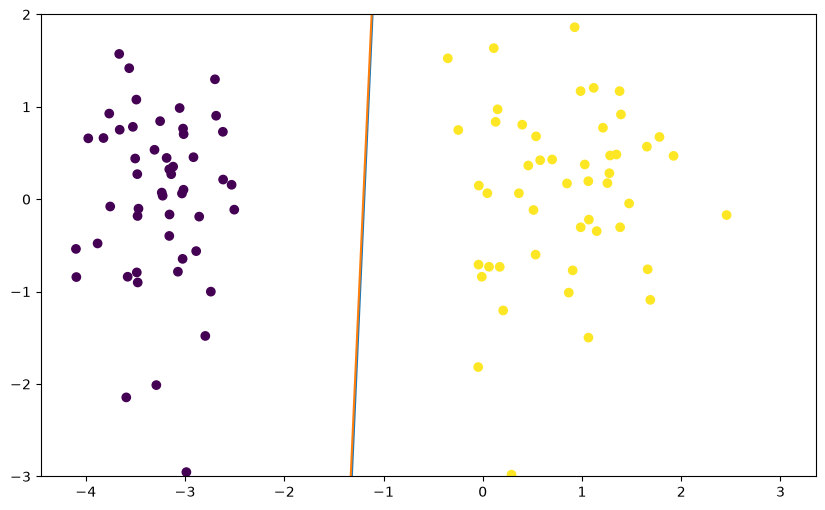

In [147]:
plt.figure(figsize=(10,6))
plt.scatter(X[:,0],X[:,1],c=y)
plt.plot(x_input,y_input)
plt.plot(x_input,y_input1)
plt.ylim(-3,2)

In [166]:
def MyLogisticRegressionStochastic(X,y):
    X=np.insert(X,0,1,axis=1)
    w=np.ones(X.shape[1])
    lr=0.5
    for i in range(20):
        for j in range(X.shape[0]):
            idx=np.random.randint(0,X.shape[0])
            xw=np.dot(X[idx],w)
            y_hat=1/(1+np.exp(-xw))
            w=w+lr*(np.dot((y[idx]-y_hat),X[idx]))
    return w[0],w[1:]


In [167]:
amrS=MyLogisticRegressionStochastic(X,y)

In [168]:
print(amrS)

(np.float64(4.935614842132111), array([4.20259468, 0.20501899]))


In [169]:
inter2=amrS[0]

In [170]:
coef2=amrS[1]

In [171]:
m2=coef2[0]/coef2[1]
b2=inter2/coef2[1]

In [172]:
y_input2=m*x_input+b

(-3.0, 2.0)

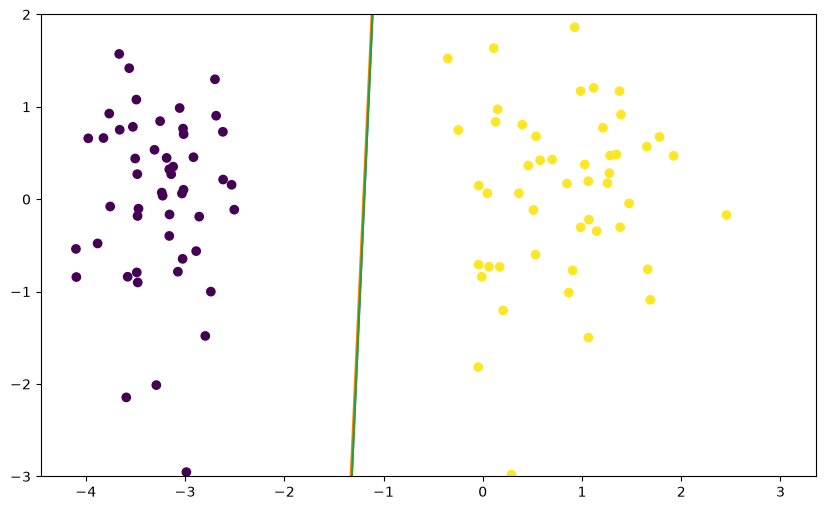

In [173]:
plt.figure(figsize=(10,6))
plt.scatter(X[:,0],X[:,1],c=y)
plt.plot(x_input,y_input)
plt.plot(x_input,y_input1)
plt.plot(x_input,y_input2)
plt.ylim(-3,2)

(-3.0, 2.0)

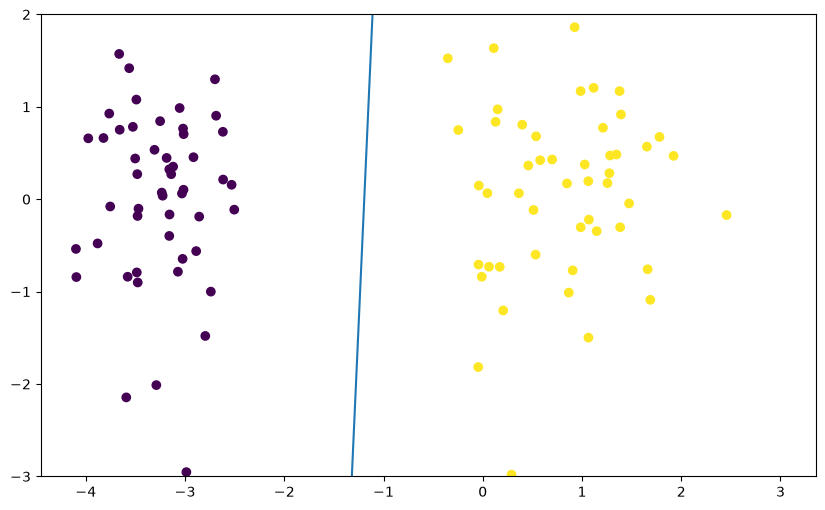

In [174]:
plt.figure(figsize=(10,6))
plt.scatter(X[:,0],X[:,1],c=y)

plt.plot(x_input,y_input2)
plt.ylim(-3,2)

(-3.0, 2.0)

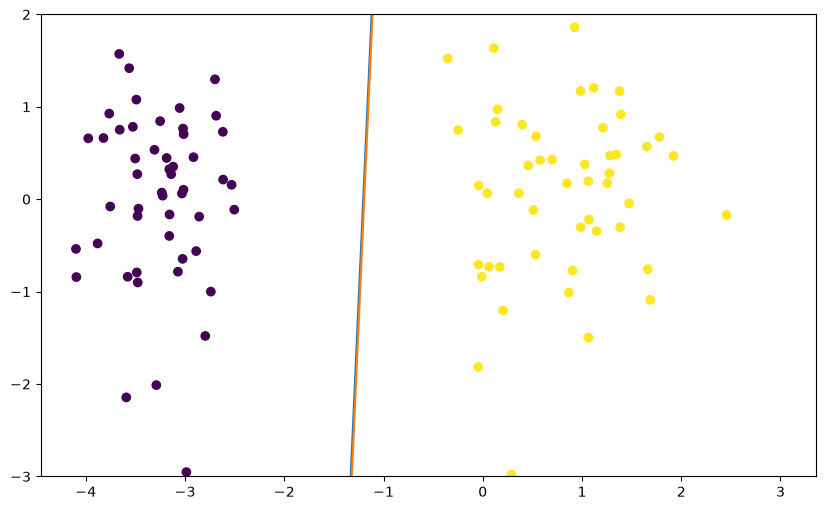

In [175]:
plt.figure(figsize=(10,6))
plt.scatter(X[:,0],X[:,1],c=y)

plt.plot(x_input,y_input1)
plt.plot(x_input,y_input2)
plt.ylim(-3,2)